# LAB 05 — Sequence Classification: RNN, LSTM và GRU

Dữ liệu IMDb. Chạy các ô từ trên xuống; bảng và biểu đồ sử dụng kết quả thực nghiệm.

**Lưu ý:** Các số trong phần nhận xét Markdown là số liệu của lần chạy đã lưu. Khi chạy lại, F1, loss, thời gian và xác suất có thể thay đổi nhẹ; hãy căn cứ bảng/biểu đồ mới để kiểm tra lại nhận xét. Markdown không tự cập nhật theo output.


## 11. Dataset inspection

Kiểm tra số mẫu, phân bố nhãn, dữ liệu thiếu/trùng lặp và độ dài review.


In [3]:
import hashlib
import re
import tarfile
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.max_colwidth", 120)

def tokenizer(text):
    text = re.sub(r"<br\s*/?>", " ", str(text).lower())
    return re.findall(r"[a-z0-9]+", text)

def clean_text(text):
    return " ".join(tokenizer(text))


In [4]:
archive = Path("/content/aclImdb_v1.tar.gz")
root = Path("/content/w4/aclImdb")

def count_files():
    return [len(list((root / split / folder).glob("*.txt")))
            for split in ["train", "test"] for folder in ["neg", "pos"]]

if count_files() != [12500] * 4:
    if not archive.exists():
        raise FileNotFoundError(f"Không tìm thấy {archive}")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall("/content/w4", filter="data")

counts = count_files()

def load_data(split):
    texts = []
    labels = []
    for label, folder in [(0, "neg"), (1, "pos")]:
        for file in sorted((root / split / folder).glob("*.txt")):
            texts.append(file.read_text(encoding="utf-8"))
            labels.append(label)
    return texts, labels

x_train_old, y_train_old = load_data("train")
x_test_old, y_test_old = load_data("test")

data = pd.DataFrame({
    "text": x_train_old + x_test_old,
    "label": y_train_old + y_test_old
})

display(data.head())
display(pd.DataFrame({
    "Tập gốc": ["train/neg", "train/pos", "test/neg", "test/pos"],
    "Số review": counts
}))


,text,label
0,Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of a...,0
1,Airport '77 starts as a brand new luxury 747 plane is loaded up with valuable paintings & such belonging to rich bus...,0
2,This film lacked something I couldn't put my finger on at first: charisma on the part of the leading actress. This i...,0
3,"Sorry everyone,,, I know this is supposed to be an ""art"" film,, but wow, they should have handed out guns at the scr...",0
4,When I was little my parents took me along to the theater to see Interiors. It was one of many movies I watched with...,0


,Tập gốc,Số review
0,train/neg,12500
1,train/pos,12500
2,test/neg,12500
3,test/pos,12500


,length
count,50000.000000
mean,235.562460
std,174.335414
min,6.000000
25%,129.000000
50%,177.000000
75%,286.000000
max,2505.000000


,Class,Count,Percentage
0,Negative,25000,50.0
1,Positive,25000,50.0


,Chỉ số,Giá trị
0,Số lớp,2.0
1,Thiếu text,0.0
2,Text rỗng,0.0
3,Thiếu nhãn,0.0
4,Review trùng,424.0
5,Nhãn mâu thuẫn,0.0
6,P75,286.0
7,P90,459.0
8,P95,601.0


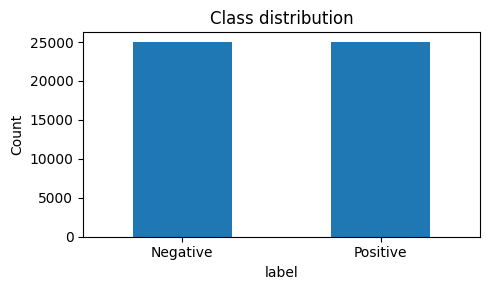

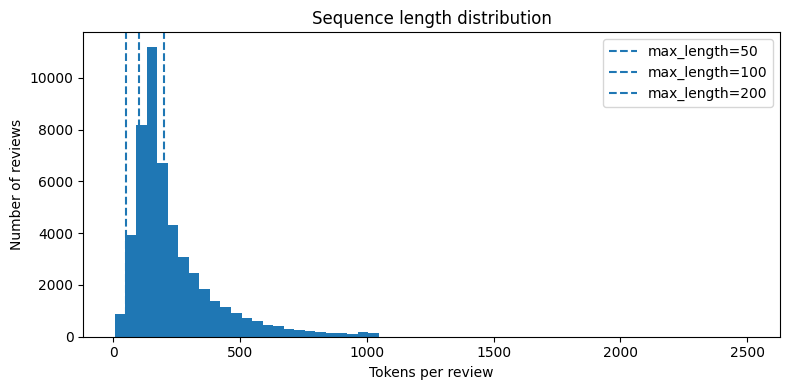

In [5]:
data["length"] = data["text"].map(lambda x: len(tokenizer(x)))
data["group"] = data["text"].map(lambda x: hashlib.md5(clean_text(x).encode("utf-8")).hexdigest())

display(data["length"].describe())

distribution = data["label"].value_counts().sort_index()
display(pd.DataFrame({
    "Class": ["Negative", "Positive"],
    "Count": distribution.values,
    "Percentage": (distribution.values / len(data) * 100).round(2)
}))

display(pd.DataFrame({
    "Chỉ số": ["Số lớp", "Thiếu text", "Text rỗng", "Thiếu nhãn",
               "Review trùng", "Nhãn mâu thuẫn", "P75", "P90", "P95"],
    "Giá trị": [data["label"].nunique(), data["text"].isna().sum(),
               data["text"].fillna("").str.strip().eq("").sum(),
               data["label"].isna().sum(), data.duplicated("group").sum(),
               (data.groupby("group")["label"].nunique() > 1).sum(),
               *data["length"].quantile([0.75, 0.90, 0.95]).round(1).tolist()]
}))

plt.figure(figsize=(5, 3))
distribution.rename({0: "Negative", 1: "Positive"}).plot.bar(rot=0)
plt.title("Class distribution")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(data["length"], bins=60)
for n in [50, 100, 200]:
    plt.axvline(n, linestyle="--", label=f"max_length={n}")
plt.title("Sequence length distribution")
plt.xlabel("Tokens per review")
plt.ylabel("Number of reviews")
plt.legend()
plt.tight_layout()
plt.show()


**Trả lời — Chọn `max_length` dựa vào đâu?**

Dựa vào histogram, median, các phân vị độ dài, tỷ lệ token giữ lại và tỷ lệ review bị cắt. Sau đó so validation F1 với thời gian, bộ nhớ ở các mức 50, 100, 200. Cắt quá ngắn có thể mất phủ định hoặc kết luận cuối bài; quá dài tốn tính toán và có thể thêm nhiễu.


## 12. Tokenization, vocabulary và chia dữ liệu

Chia train/validation/test theo nhóm text chuẩn hóa để tránh trùng lặp giữa các tập; giữ tỷ lệ nhãn. Vocabulary chỉ xây dựng từ train (`PAD = 0`, `UNK = 1`).


In [6]:
group_labels = data.groupby("group")["label"].first()
train_groups, temp_groups = train_test_split(
    group_labels.index.to_numpy(), test_size=0.3,
    random_state=SEED, stratify=group_labels.to_numpy()
)
val_groups, test_groups = train_test_split(
    temp_groups, test_size=0.5,
    random_state=SEED, stratify=group_labels.loc[temp_groups].to_numpy()
)
train = data[data["group"].isin(train_groups)].copy()
val = data[data["group"].isin(val_groups)].copy()
test = data[data["group"].isin(test_groups)].copy()

assert len(train) + len(val) + len(test) == 50000
assert set(train["group"]).isdisjoint(val["group"])
assert set(train["group"]).isdisjoint(test["group"])
assert set(val["group"]).isdisjoint(test["group"])

X_train, y_train = train["text"], train["label"]
X_val, y_val = val["text"], val["label"]
X_test, y_test = test["text"], test["label"]

display(pd.DataFrame([
    [name, len(part), round(len(part) / len(data) * 100, 2),
     int((part["label"] == 0).sum()), int((part["label"] == 1).sum())]
    for name, part in [("Train", train), ("Validation", val), ("Test", test)]
], columns=["Split", "Count", "Percentage", "Negative", "Positive"]))

,Split,Count,Percentage,Negative,Positive
0,Train,34999,70.0,17502,17497
1,Validation,7499,15.0,3745,3754
2,Test,7502,15.0,3753,3749


In [7]:
MAX_VOCAB = 20000
MAX_LEN = 200
BATCH_SIZE = 128
EMBED_DIM = 64
HIDDEN_SIZE = 64
EPOCHS = 3

counter = Counter()
for text in X_train:
    counter.update(tokenizer(text))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode(text, max_length=MAX_LEN):
    ids = [vocab.get(token, 1) for token in tokenizer(text)][:max_length]
    length = max(1, len(ids))
    ids += [0] * (max_length - len(ids))
    return ids, length

sample_ids, sample_length = encode(X_train.iloc[0])
display(pd.DataFrame({
    "Chỉ số": ["Vocabulary size", "Số token thực", "Số token sau padding"],
    "Giá trị": [len(vocab), sample_length, len(sample_ids)]
}))


,Chỉ số,Giá trị
0,Vocabulary size,20000
1,Số token thực,114
2,Số token sau padding,200


In [8]:
class ReviewDataset(Dataset):
    def __init__(self, texts, labels, max_length=MAX_LEN):
        encoded = [encode(text, max_length) for text in texts]
        self.X = torch.tensor([item[0] for item in encoded], dtype=torch.long)
        self.lengths = torch.tensor([item[1] for item in encoded], dtype=torch.long)
        self.y = torch.tensor(np.asarray(labels), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.lengths[idx], self.y[idx]

def make_loaders(max_length):
    train_dataset = ReviewDataset(X_train, y_train, max_length)
    val_dataset = ReviewDataset(X_val, y_val, max_length)
    test_dataset = ReviewDataset(X_test, y_test, max_length)
    return (
        DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True),
        DataLoader(val_dataset, batch_size=BATCH_SIZE),
        DataLoader(test_dataset, batch_size=BATCH_SIZE)
    )

train_loader, val_loader, test_loader = make_loaders(MAX_LEN)
X, lengths, y = next(iter(train_loader))
X.shape, lengths.shape, y.shape


(torch.Size([128, 200]), torch.Size([128]), torch.Size([128]))

**Trả lời — Padding và truncation khác nhau thế nào?**

Padding thêm `PAD` cho đủ độ dài và không mang nghĩa; truncation cắt token vượt `max_length`, có thể làm mất thông tin sentiment. Mô hình dùng độ dài thực để bỏ qua padding; từ ngoài vocabulary được thay bằng `UNK`.


## 13. Experiment 2 — Padding và truncation

Đo tỷ lệ token giữ lại và tỷ lệ review bị cắt ở `max_length = 50, 100, 200`. Bảng training time, Accuracy và F1 tương ứng được chạy **ở mục 20**, sau khi mô hình GRU được định nghĩa và huấn luyện theo mục 19. Không huấn luyện mô hình trùng lặp.


In [9]:
def retained_tokens(lengths, max_length):
    lengths = np.asarray(lengths)
    return 100 * np.minimum(lengths, max_length).sum() / lengths.sum()

retention_table = pd.DataFrame({
    "Max length": [50, 100, 200],
    "% tokens retained": [round(retained_tokens(train["length"], n), 2) for n in [50, 100, 200]],
    "% reviews truncated": [round(100 * (train["length"] > n).mean(), 2) for n in [50, 100, 200]]
})
display(retention_table)

,Max length,% tokens retained,% reviews truncated
0,50,21.16,97.71
1,100,40.91,87.87
2,200,68.00,41.94


**Câu hỏi mục 13 — Tăng `max_length` có luôn cải thiện performance không? Nếu `max_length` quá nhỏ thì mất gì?**

**Trả lời:** Không bảo đảm luôn cải thiện. Ở lần chạy đã lưu, F1 tăng cùng `max_length` (xem bảng thí nghiệm mục 20), nhưng chuỗi dài tốn thêm thời gian và bộ nhớ. Với `max_length` nhỏ, có thể mất các đoạn phủ định (`not`), đối lập (`but`, `however`) hoặc nhận xét cuối bài, làm sai nhãn. Tỷ lệ review bị cắt trong bảng trên cho thấy mức độ mất thông tin.


## 14. Core implementation — Simple RNN cell

Tự viết bước tính $h_t = \tanh(x_t W_{xh} + h_{t-1} W_{hh} + b_h)$ rồi so sánh với `nn.RNNCell` có cùng trọng số.

In [10]:
class SimpleRNNCell:
    def __init__(self, input_size, hidden_size):
        self.Wxh = torch.randn(input_size, hidden_size) * 0.1
        self.Whh = torch.randn(hidden_size, hidden_size) * 0.1
        self.bh = torch.zeros(hidden_size)

    def forward(self, x_t, h_prev):
        return torch.tanh(x_t @ self.Wxh + h_prev @ self.Whh + self.bh)

torch.manual_seed(SEED)
cell = SimpleRNNCell(2, 2)
x_t = torch.tensor([[1.0, 0.0]])
h_prev = torch.tensor([[0.5, 0.2]])
h_manual = cell.forward(x_t, h_prev)

cell_torch = nn.RNNCell(2, 2)
with torch.no_grad():
    cell_torch.weight_ih.copy_(cell.Wxh.T)
    cell_torch.weight_hh.copy_(cell.Whh.T)
    cell_torch.bias_ih.copy_(cell.bh)
    cell_torch.bias_hh.zero_()
h_framework = cell_torch(x_t, h_prev)

assert torch.allclose(h_manual, h_framework, atol=1e-6)
display(pd.DataFrame({
    "Cách tính": ["SimpleRNNCell", "nn.RNNCell"],
    "Hidden state": [h_manual.tolist(), h_framework.detach().tolist()]
}))


,Cách tính,Hidden state
0,SimpleRNNCell,"[[0.021686846390366554, -0.009195155464112759]]"
1,nn.RNNCell,"[[0.021686844527721405, -0.009195155464112759]]"


**Trả lời — Forward computation:**

Tại bước $t$, đầu vào $x_t$ nhân với $W_{xh}$; hidden state cũ $h_{t-1}$ nhân với $W_{hh}$. Cộng hai phần cùng bias rồi dùng `tanh` để ra hidden state mới. Vì có $h_{t-1}$, kết quả phụ thuộc thứ tự các token. Hai cách tính ở trên dùng cùng trọng số và khớp nhau.


## 15. Experiment 3 — Baseline TF-IDF + Logistic Regression và RNN

Baseline sử dụng unigram TF-IDF giống cách biểu diễn bag-of-words để so sánh với mô hình học sequence. Các chỉ số đều được tính trên cùng test set.

In [11]:
start = time.perf_counter()
tfidf = TfidfVectorizer(tokenizer=tokenizer, token_pattern=None, lowercase=False, max_features=MAX_VOCAB)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(max_iter=300, random_state=SEED)
lr_model.fit(X_train_tfidf, y_train)
lr_time = time.perf_counter() - start
lr_val_pred = lr_model.predict(X_val_tfidf)
lr_test_pred = lr_model.predict(X_test_tfidf)
display(pd.DataFrame(classification_report(
    y_test, lr_test_pred, target_names=["Negative", "Positive"],
    output_dict=True, zero_division=0
)).T.round(4))


,precision,recall,f1-score,support
Negative,0.8941,0.8844,0.8892,3753.0000
Positive,0.8855,0.8952,0.8903,3749.0000
accuracy,0.8898,0.8898,0.8898,0.8898
macro avg,0.8898,0.8898,0.8898,7502.0000
weighted avg,0.8898,0.8898,0.8898,7502.0000


Phần RNN ở đây sử dụng `nn.RNN` để huấn luyện. `SimpleRNNCell` mục 14 chỉ dùng để kiểm tra phép tính một timestep.

In [12]:
class SequenceClassifier(nn.Module):
    def __init__(self, model_type="RNN"):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), EMBED_DIM, padding_idx=0)
        if model_type == "RNN":
            self.rnn = nn.RNN(EMBED_DIM, HIDDEN_SIZE, batch_first=True)
        elif model_type == "LSTM":
            self.rnn = nn.LSTM(EMBED_DIM, HIDDEN_SIZE, batch_first=True)
        else:
            self.rnn = nn.GRU(EMBED_DIM, HIDDEN_SIZE, batch_first=True)
        self.fc = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, x, lengths):
        x = self.embedding(x)
        x = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        output, state = self.rnn(x)
        h = state[0] if isinstance(state, tuple) else state
        return self.fc(h[-1]).squeeze(1)

def evaluate_model(model, loader):
    model.eval()
    loss_fn = nn.BCEWithLogitsLoss()
    losses, y_true, y_pred = [], [], []
    with torch.no_grad():
        for X, lengths, y in loader:
            X, lengths, y = X.to(device), lengths.to(device), y.to(device)
            logits = model(X, lengths)
            losses.append(loss_fn(logits, y).item() * len(y))
            y_true.extend(y.cpu().numpy().astype(int).tolist())
            y_pred.extend((torch.sigmoid(logits) >= 0.5).cpu().numpy().astype(int).tolist())
    return sum(losses) / len(y_true), np.asarray(y_true), np.asarray(y_pred)

def scores(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": p, "Recall": r, "F1": f1
    }

def train_model(model, train_loader, val_loader, epochs=EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_count = 0, 0
        for X, lengths, y in train_loader:
            X, lengths, y = X.to(device), lengths.to(device), y.to(device)
            logits = model(X, lengths)
            loss = loss_fn(logits, y)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(y)
            total_count += len(y)
        val_loss, val_true, val_pred = evaluate_model(model, val_loader)
        row = {"Epoch": epoch, "Train Loss": total_loss / total_count,
               "Validation Loss": val_loss, "Validation F1": scores(val_true, val_pred)["F1"]}
        history.append(row)
    return pd.DataFrame(history), time.perf_counter() - start


In [13]:
models = {}
histories = {}
results = []

lr_scores = scores(y_test.to_numpy(), lr_test_pred)
results.append({"Model": "TF-IDF + LR", "Representation": "TF-IDF", "Parameters": len(lr_model.coef_.ravel()) + 1,
                "Training time (s)": lr_time, "Epochs": 0, "Max length": None, "Vocabulary": len(tfidf.vocabulary_),
                "Validation Loss": np.nan, "Validation F1": scores(y_val.to_numpy(), lr_val_pred)["F1"], **lr_scores})

torch.manual_seed(SEED)
model = SequenceClassifier("RNN").to(device)
history, seconds = train_model(model, train_loader, val_loader)
_, true, pred = evaluate_model(model, test_loader)
models["RNN"] = model
histories["RNN"] = history
results.append({"Model": "RNN", "Representation": "Embedding", "Parameters": sum(p.numel() for p in model.parameters()),
                "Training time (s)": seconds, "Epochs": EPOCHS, "Max length": MAX_LEN, "Vocabulary": len(vocab),
                "Validation Loss": history.iloc[-1]["Validation Loss"], "Validation F1": history.iloc[-1]["Validation F1"],
                **scores(true, pred)})

baseline_df = pd.DataFrame(results)
display(baseline_df.round(4))

,Model,Representation,Parameters,Training time (s),Epochs,Max length,Vocabulary,Validation Loss,Validation F1,Accuracy,Precision,Recall,F1
0,TF-IDF + LR,TF-IDF,20001,9.7469,0,NaN,20000,NaN,0.8992,0.8898,0.8855,0.8952,0.8903
1,RNN,Embedding,1288385,24.6239,3,200.0,20000,0.5631,0.7548,0.7237,0.6949,0.7970,0.7425


**Câu hỏi của mục 15 — RNN có thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng hay không?**

Kiểm tra cùng hai câu có các từ giống nhau nhưng đảo thứ tự. Dùng đúng mô hình RNN đã huấn luyện và baseline TF-IDF để so sánh xác suất Positive.

In [14]:
sentence_a = "I did not like the film but I enjoyed the ending"
sentence_b = "I enjoyed the ending but I did not like the film"
vector_difference = (tfidf.transform([sentence_a]) - tfidf.transform([sentence_b])).power(2).sum()

def predict(model, text, max_length=MAX_LEN):
    model.eval()
    ids, length = encode(text, max_length)
    x = torch.tensor([ids], dtype=torch.long, device=device)
    lengths = torch.tensor([length], dtype=torch.long, device=device)
    with torch.no_grad():
        prob = torch.sigmoid(model(x, lengths)).item()
    return int(prob >= 0.5), prob

order_table = pd.DataFrame([
    [text, lr_model.predict_proba(tfidf.transform([text]))[0, 1], predict(models["RNN"], text)[1]]
    for text in [sentence_a, sentence_b]
], columns=["Text", "TF-IDF + LR P(positive)", "RNN P(positive)"])
display(order_table)
display(pd.DataFrame({
    "TF-IDF vector difference²": [float(vector_difference)],
    "RNN probability difference": [abs(order_table.iloc[0, 2] - order_table.iloc[1, 2])]
}).round(6))


,Text,TF-IDF + LR P(positive),RNN P(positive)
0,I did not like the film but I enjoyed the ending,0.890241,0.396964
1,I enjoyed the ending but I did not like the film,0.890241,0.399819


,TF-IDF vector difference²,RNN probability difference
0,0.0,0.002855


**Trả lời:** Trong kết quả của notebook, hai câu đảo thứ tự có cùng vector unigram TF-IDF (khoảng cách bình phương bằng 0), nên Logistic Regression cho cùng xác suất. RNN cho hai xác suất khác nhau rất ít. Điều đó là bằng chứng đầu ra RNN **có phụ thuộc thứ tự token**, nhưng chưa đủ để nói mô hình đã học tốt quan hệ ngữ nghĩa theo thứ tự; cả hai dự đoán vẫn có thể cùng nhãn.

**So sánh baseline:** Bảng trên hiển thị Accuracy, Precision, Recall, F1 và thời gian cho TF-IDF + LR và RNN. Ở kết quả đã lưu, TF-IDF + LR đạt F1 cao hơn RNN; khả năng mô hình hóa thứ tự không đồng nghĩa luôn đạt F1 cao hơn.

## 19. Experiment 4 — RNN vs LSTM vs GRU

Giữ cùng train/validation/test, vocabulary, embedding dimension, hidden size, batch size, learning rate, optimizer, epochs và `max_length=200`. Chỉ thay loại recurrent layer.

In [15]:
for name in ["LSTM", "GRU"]:
    torch.manual_seed(SEED)
    model = SequenceClassifier(name).to(device)
    history, seconds = train_model(model, train_loader, val_loader)
    _, true, pred = evaluate_model(model, test_loader)
    models[name] = model
    histories[name] = history
    results.append({"Model": name, "Representation": "Embedding", "Parameters": sum(p.numel() for p in model.parameters()),
                    "Training time (s)": seconds, "Epochs": EPOCHS, "Max length": MAX_LEN, "Vocabulary": len(vocab),
                    "Validation Loss": history.iloc[-1]["Validation Loss"], "Validation F1": history.iloc[-1]["Validation F1"],
                    **scores(true, pred)})

results_df = pd.DataFrame(results)
display(results_df.round(4))
results_df.to_csv("results.csv", index=False)

,Model,Representation,Parameters,Training time (s),Epochs,Max length,Vocabulary,Validation Loss,Validation F1,Accuracy,Precision,Recall,F1
0,TF-IDF + LR,TF-IDF,20001,9.7469,0,NaN,20000,NaN,0.8992,0.8898,0.8855,0.8952,0.8903
1,RNN,Embedding,1288385,24.6239,3,200.0,20000,0.5631,0.7548,0.7237,0.6949,0.7970,0.7425
2,LSTM,Embedding,1313345,12.8312,3,200.0,20000,0.3947,0.8237,0.8203,0.8431,0.7869,0.8140
3,GRU,Embedding,1305025,12.4527,3,200.0,20000,0.3687,0.8512,0.8395,0.8337,0.8480,0.8408


**Câu hỏi của mục 19 — Kết quả thực nghiệm có phù hợp với prediction ban đầu không?**

**Trả lời — Đối chiếu với `prediction.md`:**

Trong **Prediction 2**, dự đoán LSTM có khả năng giữ và học thông tin phụ thuộc xa tốt hơn RNN đơn giản nhờ cell state và các gates. Kết quả đã lưu cho thấy LSTM có **Validation F1 = 0.8237**, **Test F1 = 0.8140**, cao hơn RNN (**0.7548** và **0.7425**). Validation Loss của LSTM (**0.3947**) cũng thấp hơn RNN (**0.5631**). Vì vậy, kết quả phân loại **phù hợp với chiều hướng dự đoán**. Tuy nhiên, các chỉ số F1 và loss trên IMDb chưa trực tiếp chứng minh LSTM đã học *long-range dependency* tốt hơn; cần xem thêm thí nghiệm về vị trí từ khóa ở mục 21.

Trong **Prediction 5**, dự đoán LSTM **không chắc chắn** đạt accuracy cao hơn RNN trên mọi dataset. Ở lần chạy này, LSTM đạt **Accuracy = 0.8203**, cao hơn RNN (**0.7237**); điều này không mâu thuẫn với prediction, nhưng cũng không thể dùng một dataset để kết luận LSTM luôn thắng.

Mô hình **GRU** không được so sánh trực tiếp trong 5 prediction của file, nhưng đề mục 19 yêu cầu đánh giá thêm GRU. GRU đạt **Validation F1 = 0.8512**, **Test F1 = 0.8408** và **Validation Loss = 0.3687**, tốt nhất trong ba mô hình recurrent ở lần chạy này. Kết quả này là **quan sát thực nghiệm**, không phải một prediction đã ghi trong `prediction.md`.

| Model | Parameters | Training time (s) | Accuracy | Precision | Recall | Test F1 | Validation F1 | Validation Loss |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| RNN | 1,288,385 | 24.62 | 0.7237 | 0.6949 | 0.7970 | 0.7425 | 0.7548 | 0.5631 |
| LSTM | 1,313,345 | 12.83 | 0.8203 | 0.8431 | 0.7869 | 0.8140 | 0.8237 | 0.3947 |
| GRU | 1,305,025 | 12.45 | 0.8395 | 0.8337 | 0.8480 | 0.8408 | 0.8512 | 0.3687 |

Về chi phí, GRU có ít tham số hơn LSTM nhưng nhiều hơn RNN. Thời gian trong bảng là **thời gian đo ở một lần chạy**, có thể thay đổi theo phần cứng và trạng thái môi trường; không thể kết luận GRU luôn nhanh hơn RNN hoặc LSTM. TF-IDF + Logistic Regression vẫn đạt **Test F1 = 0.8903**, cao hơn cả ba mô hình recurrent, dù không mô hình hóa trực tiếp thứ tự token theo cách của RNN.

**Kết luận:** Kết quả ở mục 19 ủng hộ chiều hướng của **Prediction 2** và không trái với **Prediction 5**. Các **Prediction 1, 3, 4** lần lượt liên quan đến thí nghiệm thứ tự từ ở mục 15, độ dài chuỗi ở mục 20 và ảnh hưởng của truncation ở mục 13/20, nên không dùng kết quả mục 19 để khẳng định chúng đã được kiểm chứng đầy đủ. `prediction.md` hiện có là **bản dự đoán tham khảo được soạn sau khi đã có kết quả**, không phải bằng chứng rằng các dự đoán này đã được ghi trước khi huấn luyện.


## 20. Experiment 5 — Sequence length (50, 100, 200)

Giữ cố định kiến trúc GRU, train/validation/test, optimizer và hyperparameters; chỉ thay `max_length`. Bảng kết quả cũng hoàn tất các chỉ số training time, Accuracy và F1 được yêu cầu ở mục 13. Theo dõi validation loss, test F1, token retained, thời gian và ước lượng memory.


In [16]:
length_results = []
length_models = {}
length_histories = {}

for max_length in [50, 100, 200]:
    if max_length == MAX_LEN:
        model = models["GRU"]
        history = histories["GRU"]
        seconds = float(results_df.set_index("Model").loc["GRU", "Training time (s)"])
        current_test_loader = test_loader
    else:
        length_train_loader, length_val_loader, current_test_loader = make_loaders(max_length)
        torch.manual_seed(SEED)
        model = SequenceClassifier("GRU").to(device)
        history, seconds = train_model(model, length_train_loader, length_val_loader)
    test_loss, true, pred = evaluate_model(model, current_test_loader)
    length_models[max_length] = model
    length_histories[max_length] = history
    length_results.append({
        "Max length": max_length,
        "% tokens retained": retained_tokens(train["length"], max_length),
        "% reviews truncated": 100 * (train["length"] > max_length).mean(),
        "Training time (s)": seconds,
        "Validation Loss": history.iloc[-1]["Validation Loss"],
        "Accuracy": accuracy_score(true, pred),
        "Test F1": scores(true, pred)["F1"],
        "Input memory (MB)": (len(train) + len(val) + len(test)) * max_length * 8 / (1024**2)
    })

length_df = pd.DataFrame(length_results)
display(length_df.round(4))
length_df.to_csv("sequence_length_results.csv", index=False)


,Max length,% tokens retained,% reviews truncated,Training time (s),Validation Loss,Accuracy,Test F1,Input memory (MB)
0,50,21.1571,97.7142,7.8048,0.4848,0.7618,0.7528,19.0735
1,100,40.9117,87.8739,7.7011,0.4236,0.8106,0.8110,38.1470
2,200,67.9953,41.9441,12.4527,0.3687,0.8395,0.8408,76.2939


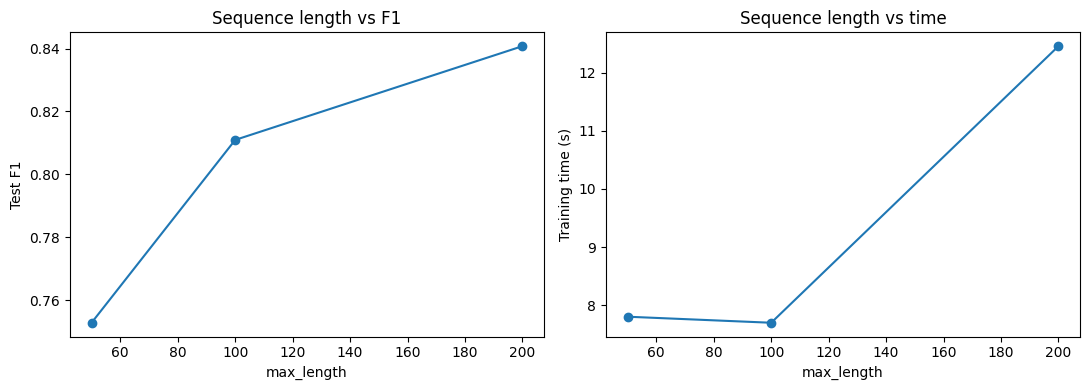

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(length_df["Max length"], length_df["Test F1"], marker="o")
axes[0].set_xlabel("max_length")
axes[0].set_ylabel("Test F1")
axes[0].set_title("Sequence length vs F1")
axes[1].plot(length_df["Max length"], length_df["Training time (s)"], marker="o")
axes[1].set_xlabel("max_length")
axes[1].set_ylabel("Training time (s)")
axes[1].set_title("Sequence length vs time")
plt.tight_layout()
plt.show()


**Câu hỏi mục 20 — Có tồn tại trade-off giữa context và computational cost không?**

**Trả lời theo kết quả đã lưu:** Khi `max_length` tăng từ 50 lên 100 rồi 200, tỷ lệ token giữ lại tăng từ **21.16% → 40.91% → 68.00%**; Test F1 của GRU tăng từ **0.7528 → 0.8110 → 0.8408**. Thời gian huấn luyện tương ứng là **7.80s → 7.70s → 12.45s**. Thời gian ở mức 50 và 100 gần tương đương, còn mức 200 tốn thời gian hơn rõ rệt. Bộ nhớ đầu vào ước tính cũng tăng khoảng **19.07 → 38.15 → 76.29 MB**.

Như vậy có **trade-off giữa giữ ngữ cảnh và chi phí tính toán**, nhưng thời gian không nhất thiết tăng đều ở mọi mức độ dài hoặc mọi lần chạy. Kết quả F1 tăng trong lần thử này không có nghĩa tăng `max_length` sẽ luôn làm mô hình tốt hơn. Khi chọn cấu hình nên dựa vào validation, không dựa vào test để chọn siêu tham số.


## 21. Experiment 6 — Long-range dependency

Tạo 6 câu chứa từ mang cảm xúc (`excellent` hoặc `terrible`) ở đầu, giữa, cuối. Kiểm tra vị trí token và xác suất Positive của cùng mô hình GRU.

In [18]:
filler = "with many scenes and familiar characters " * 12
examples = []
for sentiment_word in ["excellent", "terrible"]:
    for position, text in [
        ("Beginning", f"The movie was {sentiment_word}. " + filler),
        ("Middle", "The movie was " + filler[:len(filler)//2] + f" {sentiment_word} " + filler[len(filler)//2:]),
        ("End", "The movie was " + filler + f" {sentiment_word}.")
    ]:
        tokens = tokenizer(text)
        token_position = tokens.index(sentiment_word) + 1
        label, probability = predict(models["GRU"], text)
        examples.append([sentiment_word, position, len(tokens), token_position,
                         token_position <= MAX_LEN, label, probability])

long_range_df = pd.DataFrame(examples, columns=[
    "Keyword", "Position", "Total tokens", "Keyword token", "Retained", "Predicted", "P(positive)"
])
display(long_range_df.round(4))

spread = long_range_df.groupby("Keyword")["P(positive)"].agg(lambda s: s.max() - s.min())
display(spread.rename("Probability difference").to_frame().round(4))


,Keyword,Position,Total tokens,Keyword token,Retained,Predicted,P(positive)
0,excellent,Beginning,76,4,True,1,0.9739
1,excellent,Middle,76,40,True,1,0.9736
2,excellent,End,76,76,True,1,0.9834
3,terrible,Beginning,76,4,True,1,0.9683
4,terrible,Middle,76,40,True,1,0.9680
5,terrible,End,76,76,True,1,0.8537


,Probability difference
Keyword,
excellent,0.0098
terrible,0.1146


**Trả lời — Vị trí thông tin quan trọng có ảnh hưởng đến dự đoán không?**

**Quan sát từ output đã lưu:** Với `excellent`, xác suất Positive ở đầu/giữa/cuối là 0.9739 / 0.9736 / 0.9834 (độ chênh lớn nhất 0.0098). Với `terrible`, các giá trị là 0.9683 / 0.9680 / 0.8537 (độ chênh 0.1146). Cả sáu trường hợp đều dự đoán Positive; vị trí có thể thay đổi **độ tin cậy**, nhưng chưa làm đổi nhãn trong thử nghiệm này. Cả sáu keyword đều được giữ lại, không bị truncation.

**Giải thích lý thuyết:** GRU cập nhật hidden state qua từng token, nên mức ảnh hưởng của keyword có thể phụ thuộc vị trí và ngữ cảnh. Đây chỉ là **quan sát trên sáu câu giả lập**, không chứng minh vanishing gradient vì không trực tiếp đo gradient. Cũng cần cân nhắc tác động của các từ lặp lại xung quanh keyword.

## 22. Evaluation — Các chỉ số phân loại và computational cost

Báo cáo accuracy, precision, recall, F1, confusion matrix, số tham số, thời gian train, epochs, vocabulary size, sequence length. Các số được tổng hợp ở mục 19.

,Model,Accuracy,Precision,Recall,F1,Parameters,Training time (s),Epochs,Max length,Vocabulary
0,TF-IDF + LR,0.8898,0.8855,0.8952,0.8903,20001,9.7469,0,NaN,20000
1,RNN,0.7237,0.6949,0.7970,0.7425,1288385,24.6239,3,200.0,20000
2,LSTM,0.8203,0.8431,0.7869,0.8140,1313345,12.8312,3,200.0,20000
3,GRU,0.8395,0.8337,0.8480,0.8408,1305025,12.4527,3,200.0,20000


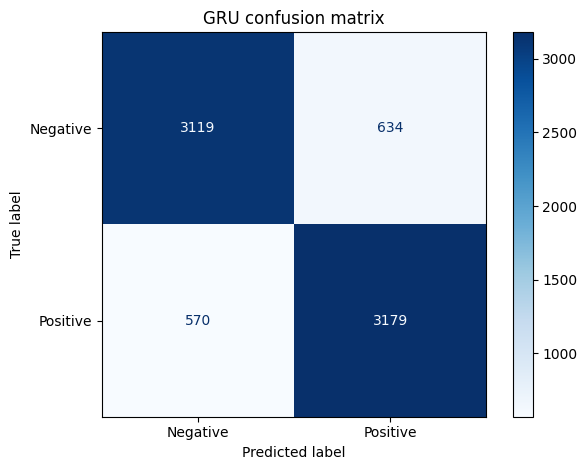

,precision,recall,f1-score,support
Negative,0.8455,0.8311,0.8382,3753.0000
Positive,0.8337,0.8480,0.8408,3749.0000
accuracy,0.8395,0.8395,0.8395,0.8395
macro avg,0.8396,0.8395,0.8395,7502.0000
weighted avg,0.8396,0.8395,0.8395,7502.0000


In [19]:
display(results_df[["Model", "Accuracy", "Precision", "Recall", "F1",
                    "Parameters", "Training time (s)", "Epochs", "Max length", "Vocabulary"]].round(4))

final_name = max(["LSTM", "GRU"], key=lambda name: results_df.set_index("Model").loc[name, "Validation F1"])
final_model = models[final_name]
_, final_true, final_pred = evaluate_model(final_model, test_loader)

ConfusionMatrixDisplay.from_predictions(final_true, final_pred, display_labels=["Negative", "Positive"], cmap="Blues")
plt.title(f"{final_name} confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

display(pd.DataFrame(classification_report(
    final_true, final_pred, target_names=["Negative", "Positive"],
    output_dict=True, zero_division=0
)).T.round(4))


**Nhận xét về các chỉ số đánh giá:**

Accuracy có thể che mất sai lệch giữa hai lớp. Precision đo mức đúng của dự đoán Positive, recall đo khả năng phát hiện Positive; F1 cân bằng hai chỉ số. Confusion matrix cho thấy FP/FN; thời gian, tham số và độ dài chuỗi cho biết chi phí.


## 23. Learning curves

Vẽ Train Loss và Validation Loss theo từng epoch cho RNN, LSTM và GRU. So sánh diễn biến của cả hai đường để đánh giá khả năng overfitting.


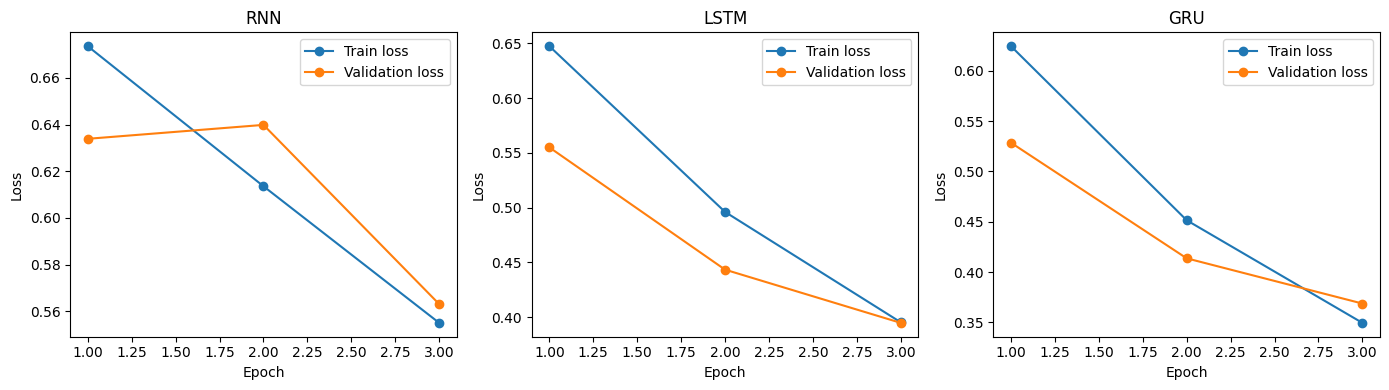

,Epoch,Train Loss,Validation Loss,Validation F1
0,1,0.6736,0.6339,0.6216
1,2,0.6136,0.6398,0.6117
2,3,0.5550,0.5631,0.7548


,Epoch,Train Loss,Validation Loss,Validation F1
0,1,0.6475,0.5550,0.7257
1,2,0.4961,0.4433,0.8040
2,3,0.3952,0.3947,0.8237


,Epoch,Train Loss,Validation Loss,Validation F1
0,1,0.6245,0.5285,0.7229
1,2,0.4515,0.4137,0.8141
2,3,0.3495,0.3687,0.8512


,Model,Best epoch,Overfitting sign
0,RNN,3,Chưa rõ
1,LSTM,3,Chưa rõ
2,GRU,3,Chưa rõ


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ["RNN", "LSTM", "GRU"]):
    history = histories[name]
    ax.plot(history["Epoch"], history["Train Loss"], marker="o", label="Train loss")
    ax.plot(history["Epoch"], history["Validation Loss"], marker="o", label="Validation loss")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

for name in ["RNN", "LSTM", "GRU"]:
    display(histories[name].round(4))

summary = []
for name, h in histories.items():
    overfit = (h.iloc[-1]["Train Loss"] < h.iloc[0]["Train Loss"] and
               h.iloc[-1]["Validation Loss"] > h["Validation Loss"].min() + 0.01)
    summary.append({"Model": name,
                    "Best epoch": int(h.loc[h["Validation Loss"].idxmin(), "Epoch"]),
                    "Overfitting sign": "Có" if overfit else "Chưa rõ"})
display(pd.DataFrame(summary))


**Câu hỏi của mục 23 — Model có dấu hiệu overfitting không?**

**Trả lời theo ba epoch đã lưu:** Chưa có bằng chứng overfitting rõ ràng. Với LSTM, Validation Loss giảm từ 0.5550 xuống 0.3947; GRU giảm từ 0.5285 xuống 0.3687, cùng chiều giảm của Train Loss. RNN có Validation Loss nhích lên ở epoch 2 (0.6339 lên 0.6398) nhưng sau đó giảm xuống 0.5631 ở epoch 3, nên không thể kết luận overfitting từ dao động nhỏ đó.

Ba epoch chưa đủ để khẳng định mô hình sẽ không overfit khi train lâu hơn; cần tiếp tục theo dõi các đường loss nếu tăng số epoch.

## 24. Error analysis

Lấy 3 review đúng và 3 review sai của mô hình được chọn theo validation F1. Xem phủ định, đảo chiều, truncation, từ lạ và ngữ cảnh.


In [21]:
def analyze_review(text, max_length=MAX_LEN):
    tokens = tokenizer(text)
    notes = []
    if any(w in tokens for w in ["not", "no", "never", "neither"]):
        notes.append("Có phủ định")
    if any(w in tokens for w in ["but", "however", "although", "though", "yet"]):
        notes.append("Có đối lập hoặc chuyển ý")
    if len(tokens) > max_length:
        notes.append(f"Bị cắt {len(tokens) - max_length} tokens")
    unknown = sum(w not in vocab for w in tokens[:max_length])
    if unknown:
        notes.append(f"Có {unknown} token UNK trong phần giữ lại")
    if not notes:
        notes.append("Cần đọc thêm về ngữ cảnh, sarcasm hoặc biểu đạt mơ hồ")
    return "; ".join(notes)

right = np.where(final_true == final_pred)[0][:3]
wrong = np.where(final_true != final_pred)[0][:3]

rows = []
for idx in list(right) + list(wrong):
    text = X_test.iloc[idx]
    rows.append({
        "Result": "Correct" if idx in right else "Incorrect",
        "Text": text[:450] + ("..." if len(text) > 450 else ""),
        "True": "Positive" if final_true[idx] else "Negative",
        "Predicted": "Positive" if final_pred[idx] else "Negative",
        "Analysis": analyze_review(text)
    })
error_df = pd.DataFrame(rows)
display(error_df)
error_df.to_csv("error_analysis.csv", index=False)


,Result,Text,True,Predicted,Analysis
0,Correct,"This film is mediocre at best. Angie Harmon is as funny as a bag of hammers. Her bitchy demeanor from ""Law and Order...",Negative,Negative,"Cần đọc thêm về ngữ cảnh, sarcasm hoặc biểu đạt mơ hồ"
1,Correct,The characters are unlikeable and the script is awful. It's a waste of the talents of Deneuve and Auteuil.,Negative,Negative,"Cần đọc thêm về ngữ cảnh, sarcasm hoặc biểu đạt mơ hồ"
2,Correct,"The action in this movie beats Sunny bhai in Gadar. Akshay Kumar possess the superpowers of Leonidus in 300, Neo in ...",Negative,Negative,Có phủ định; Có 5 token UNK trong phần giữ lại
3,Incorrect,"Sorry everyone,,, I know this is supposed to be an ""art"" film,, but wow, they should have handed out guns at the scr...",Negative,Positive,Có phủ định; Có đối lập hoặc chuyển ý; Có 1 token UNK trong phần giữ lại
4,Incorrect,...for this movie defines a new low in Bollywood and has set the standard against which all c**p must now be compare...,Negative,Positive,Có phủ định; Có đối lập hoặc chuyển ý; Bị cắt 51 tokens; Có 6 token UNK trong phần giữ lại
5,Incorrect,I figured that it's about time I let this one out. Pokémon fans are suffering in America these days. Why? Because we...,Negative,Positive,Có phủ định; Có đối lập hoặc chuyển ý; Bị cắt 838 tokens; Có 6 token UNK trong phần giữ lại


**Câu hỏi mục 24 — Lỗi này có phải do sequence modeling hay không?**

**Trả lời:** Không thể quy ngay mọi lỗi cho khả năng xử lý sequence. Review có thể bị cắt mất đoạn quyết định sentiment, chứa từ `UNK`, phủ định, đối lập hoặc cách nói mỉa mai/mơ hồ. Bảng trên đưa ra dấu hiệu để chọn các ví dụ; **nguyên nhân từng lỗi cần đọc và phân tích riêng trong `error_analysis.md`**, không tự coi các nhãn từ khóa là kết luận.


## 25. So sánh với LAB 04 — TF-IDF, Average Word2Vec, RNN, LSTM, GRU

In [22]:
comparison = pd.DataFrame({
    "Property": ["Sparse representation", "Dense representation", "Word order", "Context-dependent state", "Long dependency", "Computational cost"],
    "TF-IDF + LR": ["Yes", "No", "Limited (unigram: No)", "No", "No", "Low"],
    "Avg Word2Vec + LR": ["No", "Yes", "No", "No", "No", "Low"],
    "RNN": ["No", "Yes", "Yes", "Yes", "Limited", "Higher"],
    "LSTM": ["No", "Yes", "Yes", "Yes", "Improved", "Higher"],
    "GRU": ["No", "Yes", "Yes", "Yes", "Improved", "Higher"]
})
display(comparison)

,Property,TF-IDF + LR,Avg Word2Vec + LR,RNN,LSTM,GRU
0,Sparse representation,Yes,No,No,No,No
1,Dense representation,No,Yes,Yes,Yes,Yes
2,Word order,Limited (unigram: No),No,Yes,Yes,Yes
3,Context-dependent state,No,No,Yes,Yes,Yes
4,Long dependency,No,No,Limited,Improved,Improved
5,Computational cost,Low,Low,Higher,Higher,Higher


**Trả lời — RNN/LSTM/GRU hơn Average Word2Vec ở đâu?**

Average Word2Vec lấy trung bình embedding nên không lưu trực tiếp thứ tự. Mô hình chuỗi cập nhật hidden state theo từng token, nhờ đó có thể biểu diễn phủ định, đảo chiều và ngữ cảnh.

**Hạn chế:** xử lý tuần tự khó song song, chi phí tăng theo chiều dài, và có nguy cơ vanishing/exploding gradient. Gates cải thiện việc giữ thông tin nhưng không giải quyết triệt để dependency dài; đó là một lý do dẫn tới attention.


## 26. Application — Sentiment classifier hoàn chỉnh

Pipeline: raw review → tokenize → vocabulary → IDs → padding/truncation → Embedding → LSTM/GRU → Linear → xác suất Positive. Thử review ngắn, dài, có phủ định và có đối lập.

In [23]:
review_examples = {
    "Short": "I really enjoyed this movie.",
    "Long": "This movie started slowly with too many unnecessary scenes. " * 18 + "However, the last part was moving and I loved the ending.",
    "Negation": "I did not enjoy this movie at all.",
    "Contrast": "I thought the movie would be terrible, but it was surprisingly good."
}

application_rows = []
for kind, text in review_examples.items():
    label, prob = predict(final_model, text)
    application_rows.append({
        "Type": kind, "Text": text[:140] + ("..." if len(text) > 140 else ""),
        "Tokens": len(tokenizer(text)), "Sentiment": "Positive" if label else "Negative",
        "Probability Positive": prob,
        "Possible context": analyze_review(text)
    })
display(pd.DataFrame(application_rows).round(4))

,Type,Text,Tokens,Sentiment,Probability Positive,Possible context
0,Short,I really enjoyed this movie.,5,Positive,0.7461,"Cần đọc thêm về ngữ cảnh, sarcasm hoặc biểu đạt mơ hồ"
1,Long,This movie started slowly with too many unnecessary scenes. This movie started slowly with too many unnecessary scen...,173,Negative,0.1230,Có đối lập hoặc chuyển ý
2,Negation,I did not enjoy this movie at all.,8,Negative,0.4840,Có phủ định
3,Contrast,"I thought the movie would be terrible, but it was surprisingly good.",12,Negative,0.4444,Có đối lập hoặc chuyển ý


**Câu hỏi mục 26 — Những từ hoặc đoạn context nào có khả năng ảnh hưởng tới prediction?**

- **Short:** Từ `enjoyed` mang sắc thái tích cực. Ở output đã lưu, mô hình dự đoán **Positive**, P(Positive) khoảng **0.75**.
- **Long:** Review có **173 token**, nhỏ hơn `max_length = 200`, nên **đoạn kết không bị cắt**. Nội dung tiêu cực `started slowly`, `unnecessary scenes` lặp lại nhiều lần, còn đoạn cuối `However ... loved the ending` mang ý tích cực. Output đã lưu dự đoán **Negative**, P(Positive) khoảng **0.12**; kết quả có thể chịu ảnh hưởng của cả hai phần ngữ cảnh, không thể tự khẳng định từ nào quyết định nhãn.
- **Negation:** `not` đảo nghĩa của `enjoy`. Output đã lưu dự đoán **Negative**, P(Positive) khoảng **0.48**, khá gần ngưỡng 0.5.
- **Contrast:** `terrible, but ... surprisingly good` chuyển ý qua `but`, vế sau nghiêng về Positive. Output đã lưu dự đoán **Negative**, P(Positive) khoảng **0.44**; đây là trường hợp cần lưu ý khi kiểm tra khả năng hiểu đối lập.

Đây là phân tích các từ và ngữ cảnh **có khả năng** ảnh hưởng tới kết quả, không phải phép đo attribution. Các xác suất trên là của **lần chạy đã lưu**; nếu chạy lại làm xác suất hoặc nhãn thay đổi, cần lấy bảng output mới làm căn cứ.
